# Milestone 3 – Live Demonstration

1. Single-object image: identify the object (EfficientNet-B0, 73 Object IDs).
2. Multi-object image: identify and locate every object (YOLOv8s, 72 Object IDs).

## Setup

In [1]:
import io
import sys
from pathlib import Path

import ipywidgets as widgets
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from matplotlib import patches
from PIL import Image, ImageOps
from ultralytics import YOLO

%config InlineBackend.figure_format = "jpeg"

ROOT = Path.cwd().resolve()
while not (ROOT / "milestone1").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "milestone1" / "scripts"))
from classifier.predict import identify, load_model

DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
SAMPLES = ROOT / "milestone3" / "samples"

classifier, CLASSES = load_model(ROOT / "milestone1" / "models" / "EfficientNetB0.pt", DEVICE)
detector = YOLO(str(ROOT / "milestone2" / "models" / "yolov8s_best.pt"))

print(f"Device              : {DEVICE}")
print(f"Classifier          : EfficientNet-B0, {len(CLASSES)} Object IDs")
print(f"Detector            : YOLOv8s, {len(detector.names)} Object IDs")

Device              : mps
Classifier          : EfficientNet-B0, 73 Object IDs
Detector            : YOLOv8s, 72 Object IDs


In [2]:
COLORS = plt.get_cmap("tab20").colors


def load(source):
    img = Image.open(source) if isinstance(source, (str, Path)) else source
    return ImageOps.exif_transpose(img).convert("RGB")


def grid_shape(img):
    cols, rows = img.width / 224, img.height / 224
    if abs(cols - round(cols)) < 0.02 and abs(rows - round(rows)) < 0.02 and round(cols) * round(rows) >= 4:
        return f"{round(cols)}x{round(rows)}"
    return None


def identify_object(source, name=None, k=5):
    img = load(source)
    top = identify(classifier, CLASSES, img, DEVICE, k=k)
    print(f"Image          : {name or Path(source).name}")
    print(f"Object ID      : {top[0][0]}")
    print(f"Confidence     : {top[0][1]:.2%}")
    print("Top-5          : " + ", ".join(f"{c} ({p:.1%})" for c, p in top))
    fig, ax = plt.subplots(figsize=(4, 4))
    ax.imshow(img)
    ax.set_title(f"{top[0][0]}  {top[0][1]:.1%}", fontsize=13, fontweight="bold")
    ax.axis("off")
    plt.show()
    return top


def detect_objects(source, name=None, conf=0.5, imgsz=1120):
    img = load(source)
    r = detector.predict(img, conf=conf, imgsz=imgsz, device=DEVICE, agnostic_nms=True, verbose=False)[0]
    dets = sorted(zip(r.boxes.cls.int().tolist(), r.boxes.conf.tolist(), r.boxes.xyxy.tolist()),
                  key=lambda d: (int((d[2][1] + d[2][3]) / 2 // 224), d[2][0]))
    print(f"Image          : {name or Path(source).name}  ({img.width}x{img.height})")
    print(f"Objects found  : {len(dets)}\n")
    for i, (c, s, (x1, y1, x2, y2)) in enumerate(dets, 1):
        print(f"[{i}] Object ID  : {detector.names[c]}")
        print(f"    Confidence : {s:.2%}")
        print(f"    Location   : x1={x1:.0f}, y1={y1:.0f}, x2={x2:.0f}, y2={y2:.0f}\n")
    fig, axes = plt.subplots(1, 2, figsize=(16, 8 * img.height / img.width + 0.6))
    for ax in axes:
        ax.imshow(img)
        ax.axis("off")
    axes[0].set_title("Original Image", fontsize=14)
    axes[1].set_title(f"Detected {len(dets)} Object(s)", fontsize=14)
    fs = max(6, 11 - len(dets) // 5)
    for c, s, (x1, y1, x2, y2) in dets:
        col = COLORS[c % len(COLORS)]
        axes[1].add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=col, linewidth=2.5))
        ink = "black" if 0.299 * col[0] + 0.587 * col[1] + 0.114 * col[2] > 0.6 else "white"
        axes[1].text(x1, y1, f"{detector.names[c]} {s:.0%}", fontsize=fs, color=ink, fontweight="bold",
                     va="bottom", bbox=dict(facecolor=col, edgecolor="none", pad=1.5))
    plt.tight_layout()
    plt.show()
    return [(detector.names[c], s, b) for c, s, b in dets]

## Part 1 – Single-object identification

Image          : OBJ020_005.jpg
Object ID      : OBJ020
Confidence     : 88.14%
Top-5          : OBJ020 (88.1%), OBJ005 (2.5%), OBJ016 (1.9%), OBJ009 (0.4%), OBJ053 (0.4%)


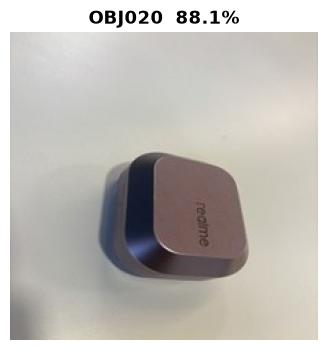


Image          : OBJ045_033.jpg
Object ID      : OBJ045
Confidence     : 88.83%
Top-5          : OBJ045 (88.8%), OBJ020 (0.7%), OBJ047 (0.4%), OBJ060 (0.3%), OBJ063 (0.3%)


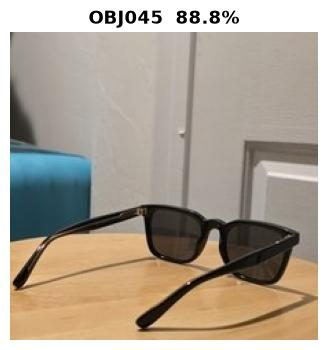


Image          : OBJ056_019.jpg
Object ID      : OBJ056
Confidence     : 88.53%
Top-5          : OBJ056 (88.5%), OBJ054 (1.2%), OBJ011 (0.6%), OBJ061 (0.5%), OBJ051 (0.4%)


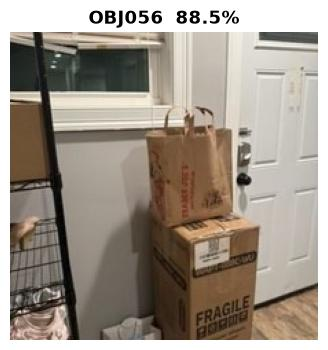

In [3]:
for f in sorted((SAMPLES / "single").glob("*.jpg")):
    identify_object(f)
    print()

## Part 2 – Multi-object detection and localization

Image          : Group1_image_1_2x2.jpg  (448x448)
Objects found  : 4

[1] Object ID  : OBJ060
    Confidence : 87.02%
    Location   : x1=26, y1=68, x2=191, y2=180

[2] Object ID  : OBJ009
    Confidence : 92.24%
    Location   : x1=299, y1=58, x2=429, y2=157

[3] Object ID  : OBJ005
    Confidence : 65.16%
    Location   : x1=30, y1=257, x2=175, y2=385

[4] Object ID  : OBJ062
    Confidence : 98.49%
    Location   : x1=324, y1=318, x2=379, y2=396



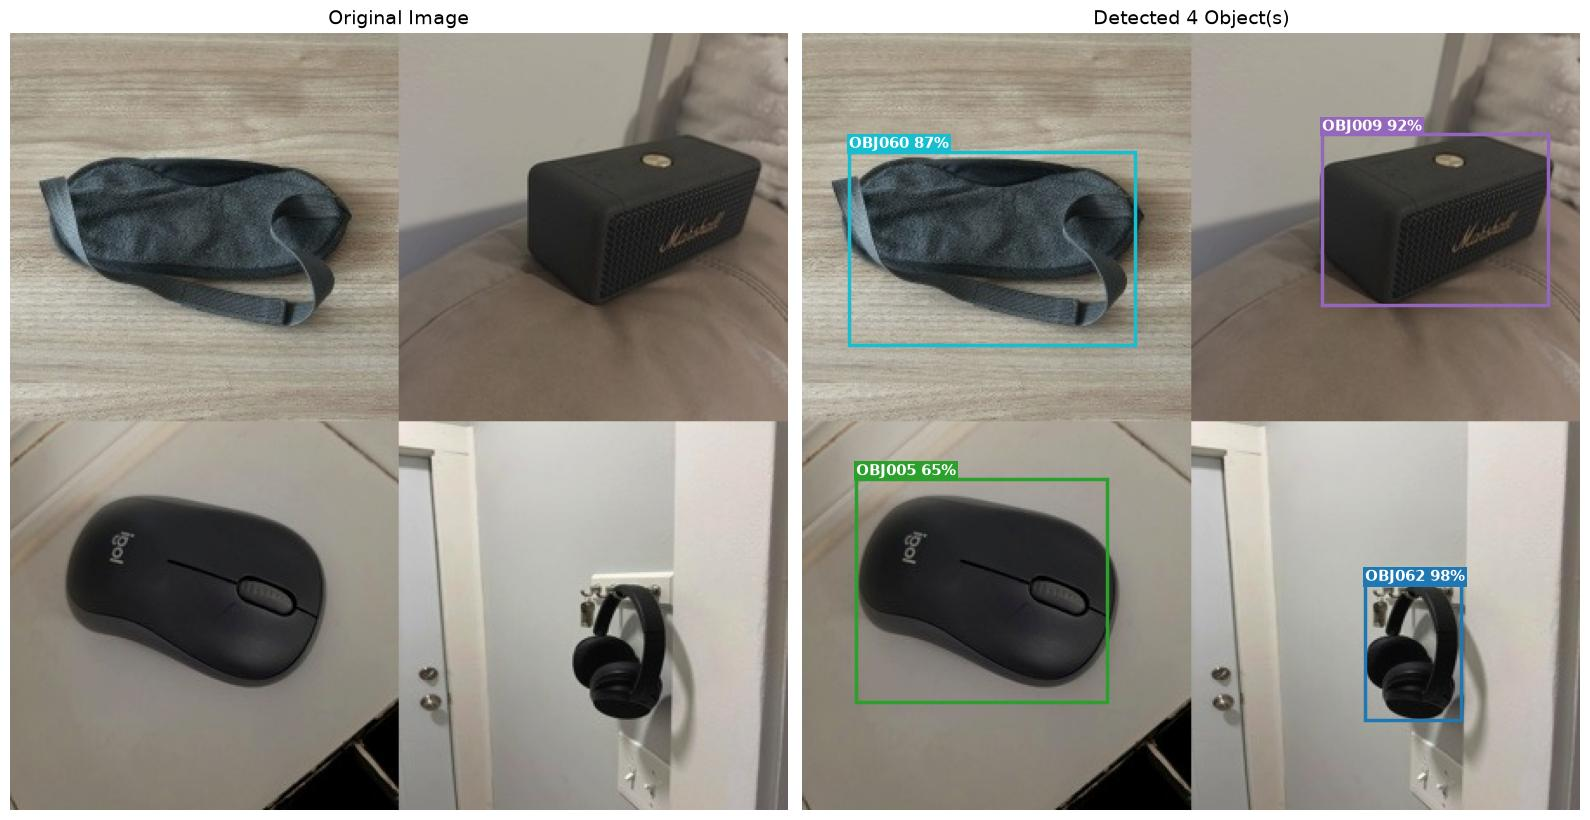

Image          : Group1_image_2_3x3.jpg  (672x672)
Objects found  : 9

[1] Object ID  : OBJ018
    Confidence : 97.24%
    Location   : x1=97, y1=71, x2=173, y2=157

[2] Object ID  : OBJ027
    Confidence : 99.13%
    Location   : x1=313, y1=104, x2=355, y2=138

[3] Object ID  : OBJ048
    Confidence : 98.41%
    Location   : x1=521, y1=110, x2=591, y2=163

[4] Object ID  : OBJ006
    Confidence : 96.70%
    Location   : x1=87, y1=279, x2=156, y2=332

[5] Object ID  : OBJ016
    Confidence : 87.70%
    Location   : x1=264, y1=225, x2=423, y2=425

[6] Object ID  : OBJ058
    Confidence : 99.95%
    Location   : x1=498, y1=270, x2=640, y2=422

[7] Object ID  : OBJ002
    Confidence : 98.60%
    Location   : x1=69, y1=483, x2=114, y2=610

[8] Object ID  : OBJ024
    Confidence : 95.00%
    Location   : x1=271, y1=451, x2=406, y2=625

[9] Object ID  : OBJ017
    Confidence : 96.11%
    Location   : x1=545, y1=571, x2=592, y2=606



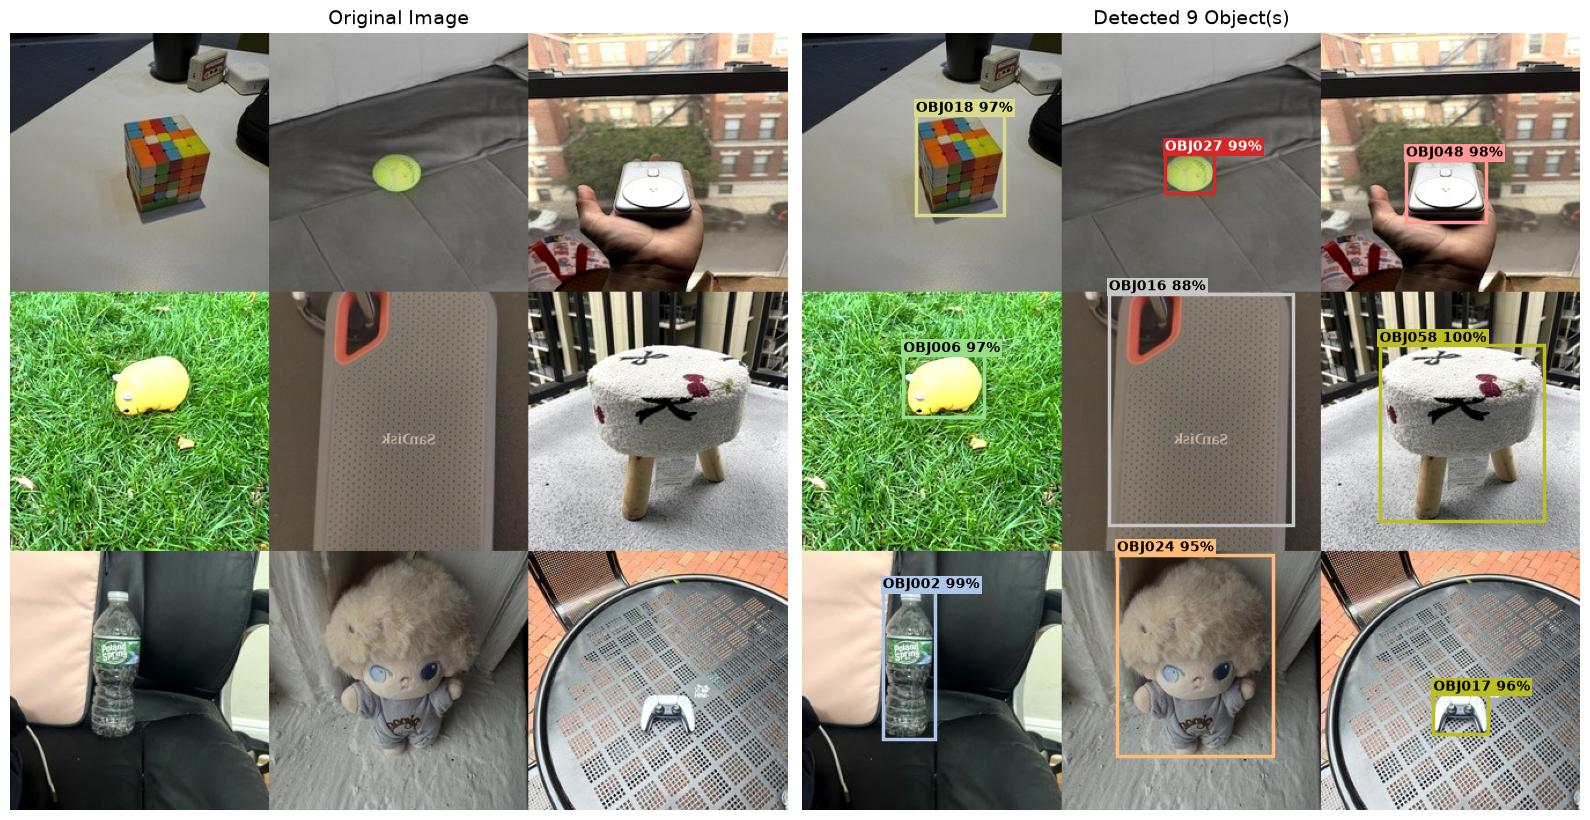

Image          : Group1_image_3_4x4.jpg  (896x896)
Objects found  : 16

[1] Object ID  : OBJ031
    Confidence : 98.82%
    Location   : x1=106, y1=44, x2=219, y2=166

[2] Object ID  : OBJ002
    Confidence : 98.98%
    Location   : x1=254, y1=0, x2=343, y2=224

[3] Object ID  : OBJ067
    Confidence : 97.95%
    Location   : x1=448, y1=10, x2=672, y2=217

[4] Object ID  : OBJ014
    Confidence : 94.82%
    Location   : x1=755, y1=81, x2=802, y2=149

[5] Object ID  : OBJ058
    Confidence : 94.12%
    Location   : x1=101, y1=311, x2=152, y2=373

[6] Object ID  : OBJ060
    Confidence : 93.79%
    Location   : x1=234, y1=249, x2=436, y2=421

[7] Object ID  : OBJ068
    Confidence : 96.24%
    Location   : x1=473, y1=236, x2=671, y2=381

[8] Object ID  : OBJ047
    Confidence : 95.85%
    Location   : x1=709, y1=261, x2=866, y2=445

[9] Object ID  : OBJ017
    Confidence : 98.43%
    Location   : x1=66, y1=556, x2=161, y2=623

[10] Object ID  : OBJ005
    Confidence : 97.16%
    Location

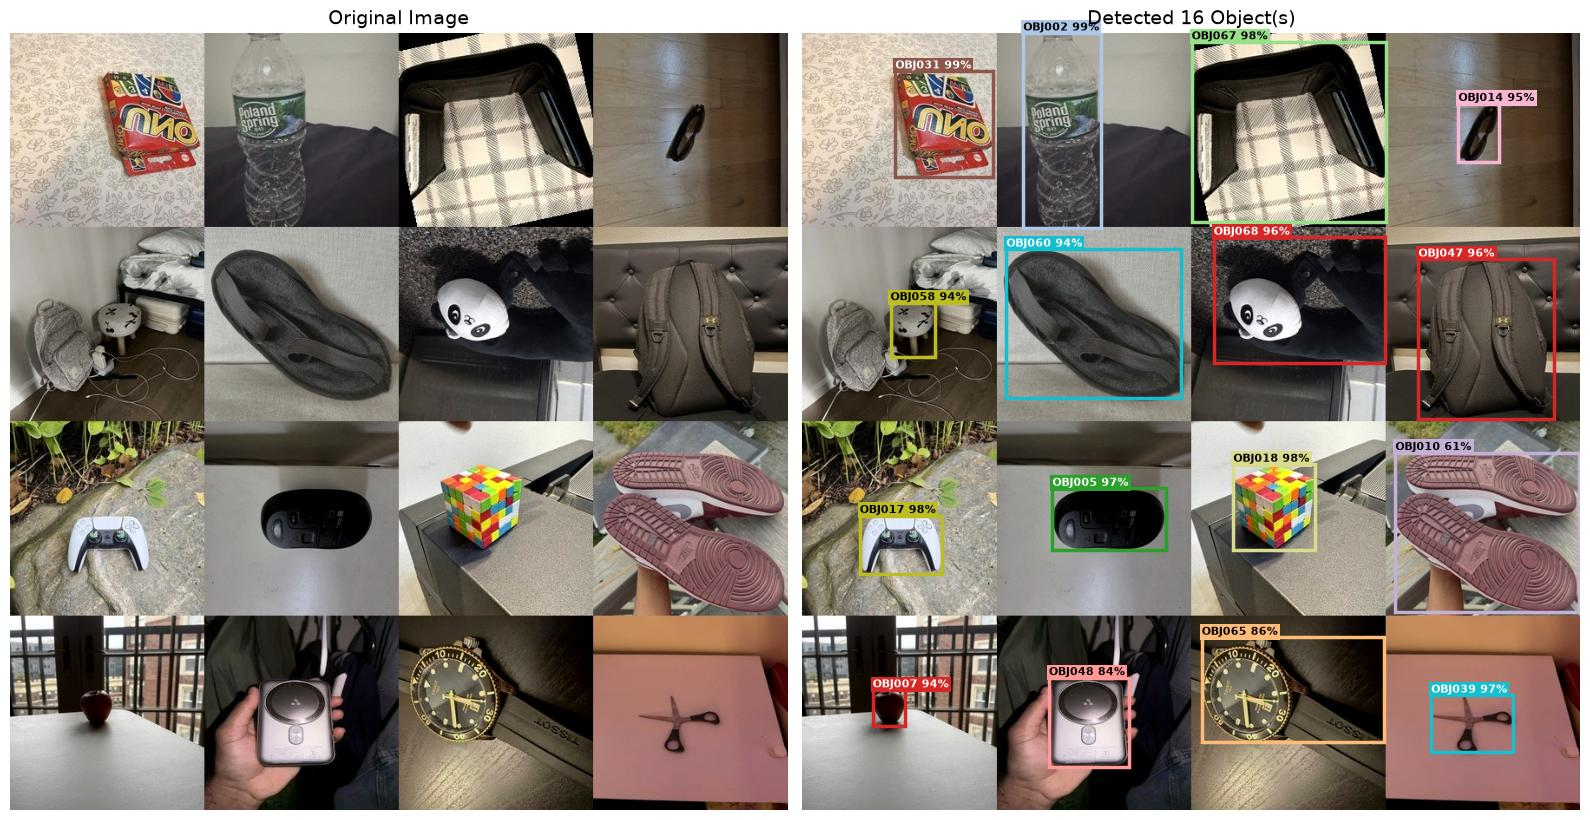

Image          : Group1_image_4_5x4.jpg  (1120x896)
Objects found  : 20

[1] Object ID  : OBJ072
    Confidence : 94.56%
    Location   : x1=66, y1=46, x2=224, y2=222

[2] Object ID  : OBJ046
    Confidence : 98.23%
    Location   : x1=290, y1=42, x2=430, y2=131

[3] Object ID  : OBJ036
    Confidence : 98.05%
    Location   : x1=490, y1=96, x2=628, y2=181

[4] Object ID  : OBJ001
    Confidence : 97.69%
    Location   : x1=745, y1=45, x2=825, y2=125

[5] Object ID  : OBJ055
    Confidence : 98.04%
    Location   : x1=998, y1=85, x2=1037, y2=140

[6] Object ID  : OBJ007
    Confidence : 98.15%
    Location   : x1=62, y1=283, x2=178, y2=400

[7] Object ID  : OBJ013
    Confidence : 57.87%
    Location   : x1=287, y1=294, x2=341, y2=353

[8] Object ID  : OBJ057
    Confidence : 74.68%
    Location   : x1=492, y1=336, x2=574, y2=386

[9] Object ID  : OBJ009
    Confidence : 92.15%
    Location   : x1=743, y1=351, x2=802, y2=382

[10] Object ID  : OBJ030
    Confidence : 98.03%
    Locatio

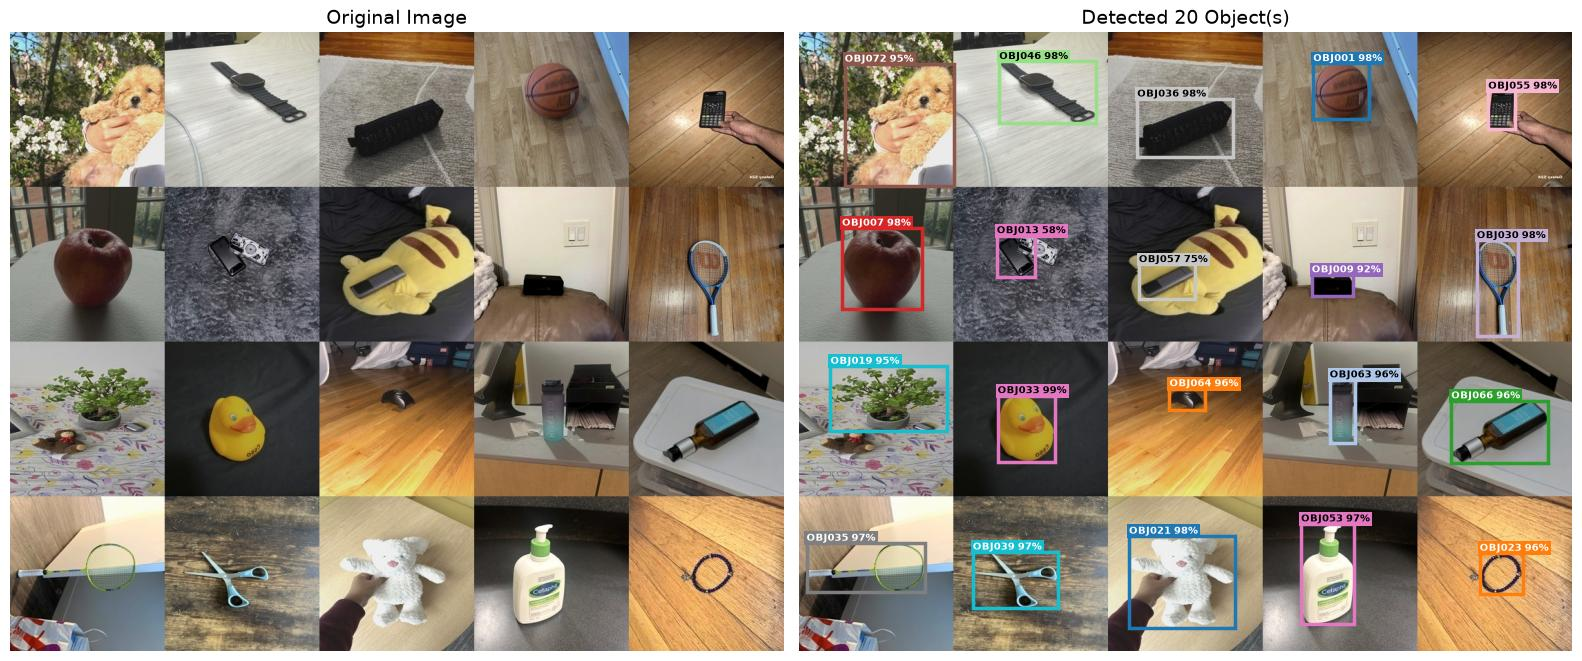

Image          : Group1_image_5_5x5.jpg  (1120x1120)
Objects found  : 25

[1] Object ID  : OBJ043
    Confidence : 98.76%
    Location   : x1=20, y1=30, x2=178, y2=176

[2] Object ID  : OBJ072
    Confidence : 94.92%
    Location   : x1=299, y1=76, x2=434, y2=153

[3] Object ID  : OBJ022
    Confidence : 96.60%
    Location   : x1=508, y1=0, x2=651, y2=216

[4] Object ID  : OBJ007
    Confidence : 98.64%
    Location   : x1=746, y1=50, x2=857, y2=162

[5] Object ID  : OBJ033
    Confidence : 97.70%
    Location   : x1=983, y1=56, x2=1041, y2=139

[6] Object ID  : OBJ040
    Confidence : 97.66%
    Location   : x1=54, y1=301, x2=130, y2=349

[7] Object ID  : OBJ065
    Confidence : 95.55%
    Location   : x1=224, y1=357, x2=448, y2=409

[8] Object ID  : OBJ020
    Confidence : 91.84%
    Location   : x1=537, y1=353, x2=580, y2=373

[9] Object ID  : OBJ061
    Confidence : 98.78%
    Location   : x1=701, y1=312, x2=817, y2=408

[10] Object ID  : OBJ010
    Confidence : 80.18%
    Locatio

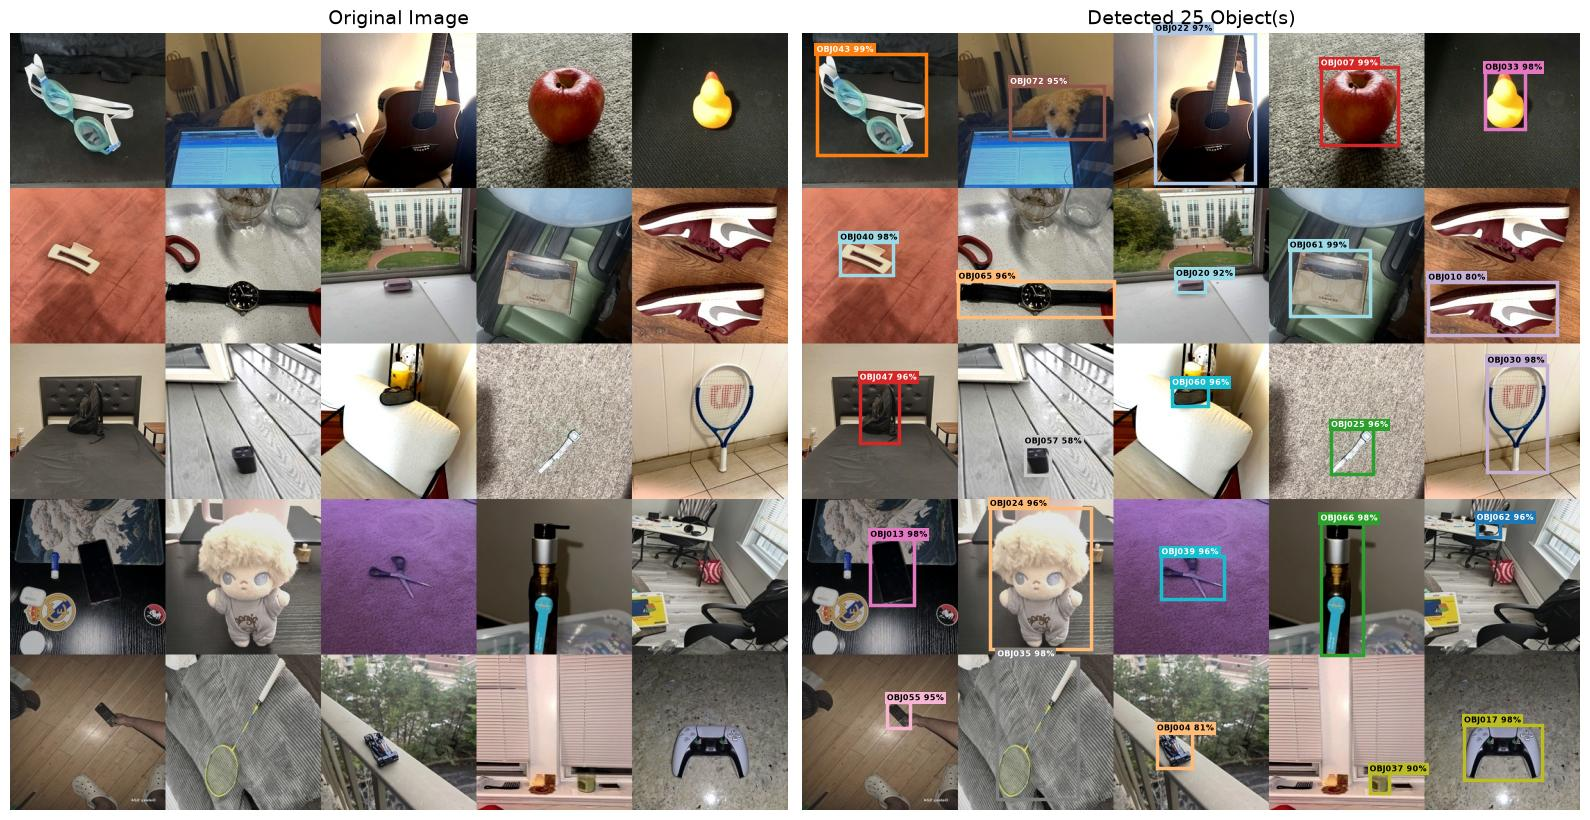

In [4]:
for f in sorted((SAMPLES / "multi").glob("*.jpg")):
    detect_objects(f)

## Upload an image

In [5]:
mode = widgets.ToggleButtons(options=["Multi-object", "Single-object"], value="Multi-object")
upload = widgets.FileUpload(accept="image/*", multiple=True, description="Upload image")
conf = widgets.FloatSlider(value=0.5, min=0.05, max=0.95, step=0.05, description="confidence")
again = widgets.Button(description="Run again")
out = widgets.Output()


def run(_=None):
    out.clear_output()
    with out:
        for f in upload.value:
            img = Image.open(io.BytesIO(bytes(f["content"])))
            shape = grid_shape(img)
            if mode.value == "Single-object" and shape:
                print(f"{f['name']} is a {shape} multi-object grid, so every object is detected instead.\n")
                detect_objects(img, f["name"], conf=conf.value)
            elif mode.value == "Single-object":
                identify_object(img, f["name"])
            else:
                detect_objects(img, f["name"], conf=conf.value)


upload.observe(run, names="value")
again.on_click(run)
display(widgets.VBox([widgets.HBox([mode, upload]), widgets.HBox([conf, again]), out]))